# GoalScope head-budget (sparsity) sweep

Reproduces the GoalScope head-budget sweep figures for **Qwen2.5-Coder-32B-Instruct**
(`additive_norm`, alpha=0.1). Pure parsing of `summary.json` per head-set leaf.

- **Metric:** `hard_yes` = fraction of anchors the grading oracle scored YES.
- **faithfulness** grades an NL description; **causality** grades a C++ re-implementation.
  Different rubrics -> compare within a metric, never faith-vs-causality.
- Every curve is the **mean over the four pre-implementation pivots**
  (`prev_end, indent, var, eq`) -- NOT `overall`, and `first_impl` is excluded everywhere.

Head budgets swept: 5, 10, 25, 50, 100, **122** (the chosen threshold-selected `goal` set),
150, 200, 250, 300. The lambda that produced each cut is mixed (snap/lam100 for k<=100,
threshold@0.9 for 122, lam20 for 150-250, lam5 for 300) -- a dip is not purely a head-count effect.

In [1]:
import os, sys
_d=os.getcwd()
while _d!='/' and not os.path.isdir(os.path.join(_d,'src')): _d=os.path.dirname(_d)
sys.path.insert(0,_d); os.chdir(_d)
from src.utils import env_utils
sys.path.insert(0, os.path.join(env_utils.PROJECT_ROOT,'notebooks','fig_n_table_generators'))

In [2]:
import glob, re, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rich import print as rich_print
from rich.table import Table
from rich.box import SIMPLE_HEAVY

import figstyle
figstyle.set_style()

MODEL = "Qwen2.5-Coder-32B-Instruct"
STRATEGY, ALPHA = "additive_norm", "0.1"
PIVOTS = figstyle.PIVOTS            # ["prev_end","indent","var","eq"] -- NEVER first_impl
COLOR = figstyle.MODEL_COLOR[MODEL]
GROUP = "sparsity_ablation"
print("pivots:", PIVOTS)

pivots: ['prev_end', 'indent', 'var', 'eq']


In [3]:
# ── parse every head-set leaf's summary.json ────────────────────────────────
BASE = os.path.join(env_utils.PROJECT_ROOT, "results", "evaluation", "goalscope", MODEL)

def head_count(leaf_name: str) -> int:
    """Head budget from the leaf dir name. json:...top<k> -> k; the canonical
    threshold-selected `goal` set (heads=goal__..., no `json:`) is 122."""
    m = re.search(r"top(\d+)", leaf_name)
    if m:
        return int(m.group(1))
    if leaf_name.startswith("heads=goal__") and "json" not in leaf_name:
        return 122
    raise ValueError(f"cannot parse head count from {leaf_name!r}")

def load_metric(metric: str) -> pd.DataFrame:
    root = os.path.join(BASE, metric, STRATEGY, ALPHA)
    rows = []
    for leaf in glob.glob(os.path.join(root, "heads=*")):
        if not re.match(r"heads=(json:)?goal__", os.path.basename(leaf)):
            continue  # goal-head budgets only (skip e.g. the json:control122 control run)
        sm = os.path.join(leaf, "summary.json")
        if not os.path.exists(sm):
            continue
        s = json.load(open(sm))
        k = head_count(os.path.basename(leaf))
        by = s["by_anchor"]
        row = {"n_heads": k, "metric": metric,
               "overall": s["overall"]["hard_yes"],
               "n_records": s.get("n_records"),
               "mean_pivots": float(np.mean([by[p]["hard_yes"] for p in PIVOTS]))}
        row.update({p: by[p]["hard_yes"] for p in PIVOTS})
        rows.append(row)
    return pd.DataFrame(rows).sort_values("n_heads").reset_index(drop=True)

faith = load_metric("faithfulness")
caus  = load_metric("causality")
KS = sorted(faith.n_heads.unique())
assert KS == [5,10,25,50,100,122,150,200,250,300], KS
print("head budgets:", KS)
faith

head budgets: [np.int64(5), np.int64(10), np.int64(25), np.int64(50), np.int64(100), np.int64(122), np.int64(150), np.int64(200), np.int64(250), np.int64(300)]


,n_heads,metric,overall,n_records,mean_pivots,prev_end,indent,var,eq
0,5,faithfulness,0.445850,1265,0.362648,0.098814,0.371542,0.233202,0.747036
1,10,faithfulness,0.715415,1265,0.667984,0.335968,0.743083,0.683794,0.909091
2,25,faithfulness,0.791304,1265,0.750000,0.450593,0.798419,0.814229,0.936759
3,50,faithfulness,0.817391,1265,0.782609,0.561265,0.865613,0.747036,0.956522
4,100,faithfulness,0.867194,1265,0.839921,0.608696,0.901186,0.881423,0.968379
5,122,faithfulness,0.879051,1265,0.852767,0.588933,0.944664,0.905138,0.972332
6,150,faithfulness,0.859289,1265,0.830040,0.529644,0.897233,0.928854,0.964427
7,200,faithfulness,0.879842,1265,0.854743,0.616601,0.916996,0.905138,0.980237
8,250,faithfulness,0.852174,1265,0.823123,0.498024,0.893281,0.924901,0.976285
9,300,faithfulness,0.874308,1265,0.848814,0.604743,0.901186,0.920949,0.968379


## Figure 1 — `sparsity_sweep` (mean over pivots)

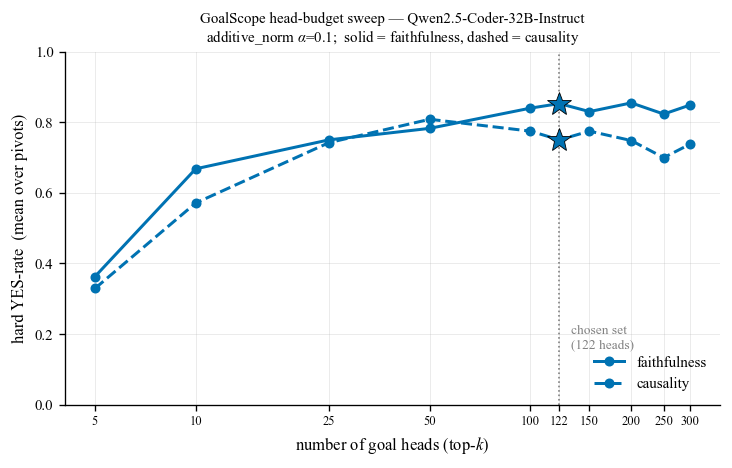

In [5]:
# ── Figure 1: two lines, mean-over-pivots vs head budget ────────────────────
fig, ax = plt.subplots(figsize=(6.2, 4.0))
for metric, df, ls in [("faithfulness", faith, "-"), ("causality", caus, "--")]:
    ax.plot(df.n_heads, df.mean_pivots, marker="o", ls=ls, color=COLOR, lw=1.8,
            ms=5, label=metric, zorder=3)
    # highlight the chosen 122-head set
    y122 = float(df.loc[df.n_heads == 122, "mean_pivots"].iloc[0])
    ax.plot([122], [y122], marker="*", ms=15, color=COLOR,
            markeredgecolor="black", markeredgewidth=0.5, zorder=5)

ax.axvline(122, color="grey", ls=":", lw=1, zorder=1)
ax.annotate("chosen set\n(122 heads)", xy=(122, ax.get_ylim()[0]),
            xytext=(132, 0.16), fontsize=8, color="grey")

ax.set_xscale("log")
ax.set_xticks(KS)
ax.set_xticklabels([str(k) for k in KS], fontsize=7.5)
ax.minorticks_off()
ax.set_xlabel("number of goal heads (top-$k$)")
ax.set_ylabel("hard YES-rate  (mean over pivots)")
ax.set_ylim(0, 1)
ax.set_title(f"GoalScope head-budget sweep — {MODEL}\nadditive_norm $\\alpha$=0.1;  "
             "solid = faithfulness, dashed = causality", fontsize=9)
ax.legend(frameon=False, fontsize=9, loc="lower right")
plt.tight_layout()
figstyle.save_fig(fig, GROUP, "sparsity_sweep")
plt.show()

## Figure 2 — `sparsity_by_pivot` (small multiples, one panel per pivot)

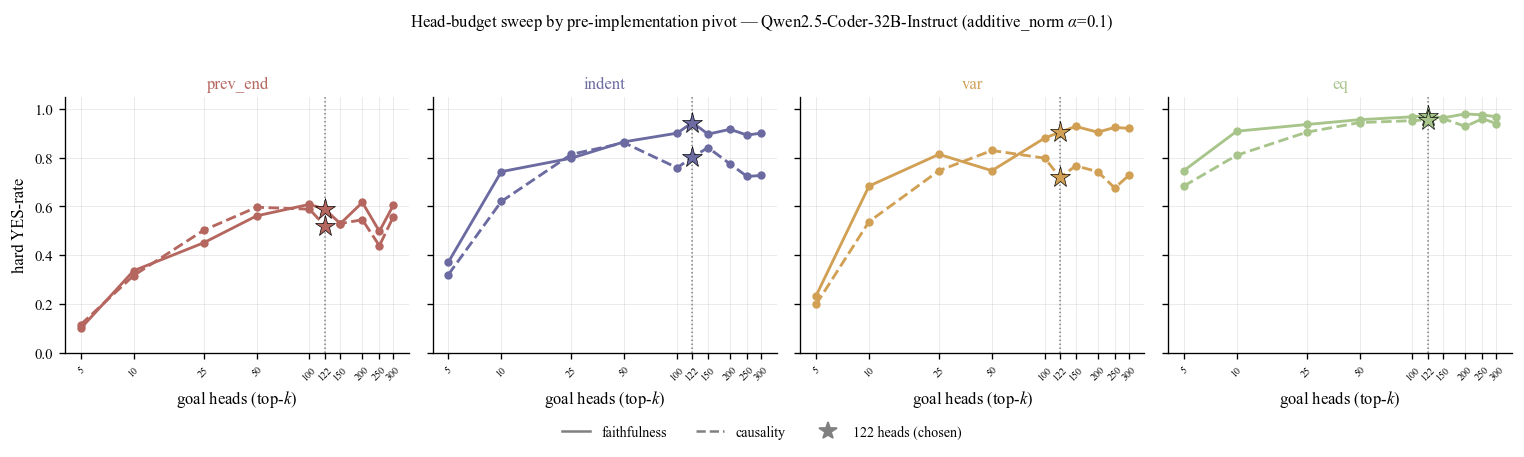

In [6]:
# ── Figure 2: per-pivot small multiples (appendix head_budget_preimplementation) ──
fig, axes = plt.subplots(1, len(PIVOTS), figsize=(3.2 * len(PIVOTS), 3.4), sharey=True)
for ax, piv in zip(axes, PIVOTS):
    pc = figstyle.PIVOT_COLOR[piv]
    for metric, df, ls in [("faithfulness", faith, "-"), ("causality", caus, "--")]:
        ax.plot(df.n_heads, df[piv], marker="o", ls=ls, color=pc, lw=1.7, ms=4,
                label=metric, zorder=3)
        y122 = float(df.loc[df.n_heads == 122, piv].iloc[0])
        ax.plot([122], [y122], marker="*", ms=13, color=pc,
                markeredgecolor="black", markeredgewidth=0.4, zorder=5)
    ax.axvline(122, color="grey", ls=":", lw=0.9, zorder=1)
    ax.set_xscale("log")
    ax.set_xticks(KS)
    ax.set_xticklabels([str(k) for k in KS], fontsize=6, rotation=45)
    ax.minorticks_off()
    ax.set_title(piv, fontsize=10, color=pc, pad=5)
    ax.set_xlabel("goal heads (top-$k$)")
    ax.set_ylim(0, 1.05)
axes[0].set_ylabel("hard YES-rate")

from matplotlib.lines import Line2D
handles = [Line2D([], [], color="grey", ls="-", label="faithfulness"),
           Line2D([], [], color="grey", ls="--", label="causality"),
           Line2D([], [], color="grey", ls="", marker="*", ms=11, label="122 heads (chosen)")]
fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, -0.06),
           ncol=3, frameon=False, fontsize=8.5)
fig.suptitle(f"Head-budget sweep by pre-implementation pivot — {MODEL} (additive_norm "
             "$\\alpha$=0.1)", y=1.02, fontsize=10)
plt.tight_layout()
figstyle.save_fig(fig, GROUP, "sparsity_by_pivot")
plt.show()

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/sparsity_ablation/source_comparison.pdf


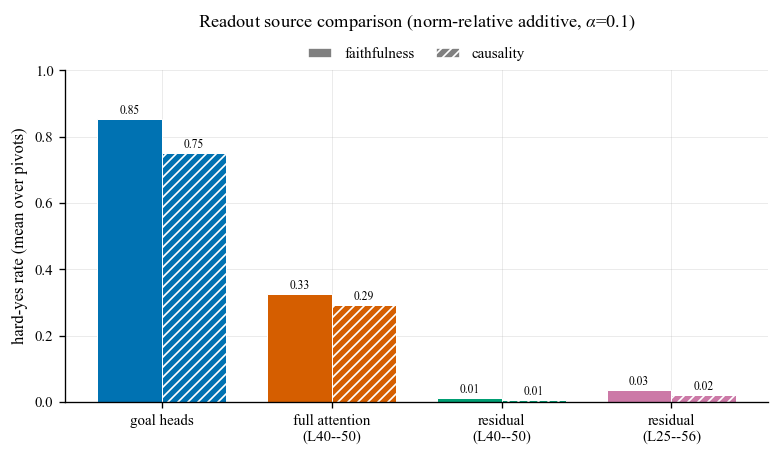

In [10]:
# ── Figure (paper fig:heads-vs-residual): goal-head readout by pivot + L40--50 baselines ──
# Merged view: goal-head readout broken out per pre-impl pivot + the mean, then only the
# L40--50 full-attention and residual baselines appended for comparison (additive, alpha=0.1).
import glob, json, numpy as np, matplotlib.pyplot as plt
import figstyle as F; F.set_style()
M='Qwen2.5-Coder-32B-Instruct'; PIV=F.PIVOTS
def by_pivot(strat,pat,mode):
    g=glob.glob(f'results/evaluation/goalscope/{M}/{mode}/{strat}/{pat}/summary.json')
    if not g: return {a:np.nan for a in PIV}
    d=json.load(open(g[0]))['by_anchor']; return {a:float(d[a]['hard_yes']) for a in PIV}
def mean4(strat,pat,mode):
    d=by_pivot(strat,pat,mode); return float(np.nanmean([d[a] for a in PIV]))

# goal heads, per pivot (additive_norm/0.1)
gh_f=by_pivot('additive_norm/0.1','heads=goal__*','faithfulness')
gh_c=by_pivot('additive_norm/0.1','heads=goal__*','causality')
# appended L40--50 baselines (resid_norm/0.1), aggregated as mean over the four pivots
BASE=[('full attention\n(L40–50)','heads=attn:L40-50:mean*','#808080'),
      ('residual\n(L40–50)',      'heads=resid:L40-50:mean*','#c8c8c8')]

labels=list(PIV)+['mean']+[b[0] for b in BASE]
cols  =[F.PIVOT_COLOR[a] for a in PIV]+['#4682B4']+[b[2] for b in BASE]
faith =[gh_f[a] for a in PIV]+[np.mean([gh_f[a] for a in PIV])]+[mean4('resid_norm/0.1',b[1],'faithfulness') for b in BASE]
caus  =[gh_c[a] for a in PIV]+[np.mean([gh_c[a] for a in PIV])]+[mean4('resid_norm/0.1',b[1],'causality')    for b in BASE]

SP=0.70                                   # group spacing (<1 -> tighter groups)
pos=np.arange(len(labels))*SP
fig,ax=plt.subplots(figsize=(6.0,3.9)); w=0.28  # thinner bars, narrower fig, tighter groups
for xi in range(len(labels)):
    ax.bar(pos[xi]-w/2, faith[xi], w, **F.metric_kw('faithfulness', cols[xi]))
    ax.bar(pos[xi]+w/2, caus[xi],  w, **F.metric_kw('causality',    cols[xi]))
    ax.text(pos[xi]-w/2, faith[xi]+.015, f'{faith[xi]:.2f}', ha='center', va='bottom', fontsize=6)
    ax.text(pos[xi]+w/2, caus[xi]+.015,  f'{caus[xi]:.2f}',  ha='center', va='bottom', fontsize=6)
ax.set_xticks(pos); ax.set_xticklabels(labels); ax.set_xlim(-w-0.18, pos[-1]+w+0.18)
ax.set_ylabel('hard-yes rate (mean over pivots)'); ax.set_ylim(0,1.0)
ax.xaxis.grid(False)  # keep only horizontal gridlines
ax.set_title('Goal-head readout by pivot vs. baselines ($\\alpha$=0.1)')
ax.axvline((len(PIV)-0.5)*SP, color='#ccc', lw=.8, ls=':')   # goal-head pivots | mean
ax.axvline((len(PIV)+0.5)*SP, color='#ccc', lw=.8, ls=':')   # mean | L40--50 baselines
_h=F.metric_legend_handles(); F.legend_top(ax, handles=_h, labels=[h.get_label() for h in _h])
fig.tight_layout(); print('saved', F.save_fig(fig,'sparsity_ablation','source_comparison')); plt.show()


saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/sparsity_ablation/ablation_results.pdf


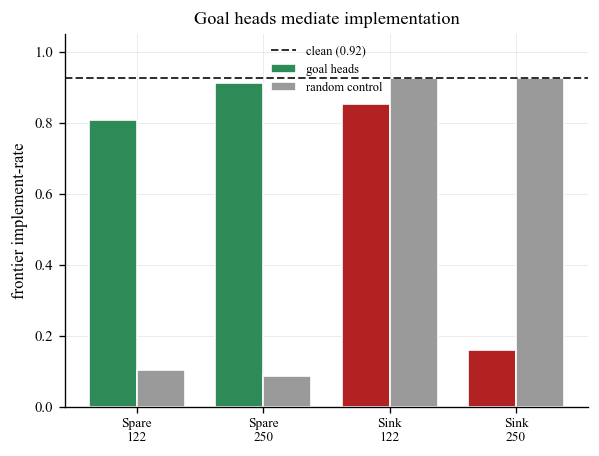

In [11]:
# STANDALONE ablation-results panel (the causal-involvement / tab:goal-ablation figure), split out
# of the old paired figure so ablation can pair with the temporal-persistence curves in the main text.
import glob, json, numpy as np, matplotlib.pyplot as plt
import figstyle as F; F.set_style()
MODEL = 'Qwen2.5-Coder-32B-Instruct'
ABL = f'results/evaluation/ablation/{MODEL}'
def abl(axis, strat, bud, key):
    g = [q for q in glob.glob(f'{ABL}/{axis}/*/summary.json')
         if f'strat={strat}__' in q and bud in q and '__ctrl=later_half' in q]
    return json.load(open(g[0]))['overall'][key] if g else np.nan
clean = abl('necessity', 'sink', 'goal250', 'baseline')
groups = ['Spare\n122', 'Spare\n250', 'Sink\n122', 'Sink\n250']
goal = [abl('sufficiency', 'blind_span', 'goal122', 'ablated'), abl('sufficiency', 'blind_span', 'goal250', 'ablated'),
        abl('necessity', 'sink', 'goal122', 'ablated'), abl('necessity', 'sink', 'goal250', 'ablated')]
rand = [abl('sufficiency', 'blind_span', 'goal122', 'control'), abl('sufficiency', 'blind_span', 'goal250', 'control'),
        abl('necessity', 'sink', 'goal122', 'control'), abl('necessity', 'sink', 'goal250', 'control')]
gcol = ['seagreen', 'seagreen', 'firebrick', 'firebrick']
fig, ax = plt.subplots(figsize=(5.1, 3.9))
x = np.arange(len(groups)); w = 0.38
ax.bar(x - w/2, goal, w, color=gcol, edgecolor='white', label='goal heads')
ax.bar(x + w/2, rand, w, color='#9a9a9a', edgecolor='white', label='random control')
ax.axhline(clean, ls='--', lw=1.2, color='#333', label=f'clean ({clean:.2f})')
ax.set_xticks(x); ax.set_xticklabels(groups, fontsize=8)
ax.set_ylabel('frontier implement-rate'); ax.set_ylim(0, 1.05)
ax.set_title('Goal heads mediate implementation')
ax.legend(fontsize=7.5, frameon=False, loc='upper center', ncol=1)
fig.tight_layout()
print('saved', F.save_fig(fig, 'sparsity_ablation', 'ablation_results')); plt.show()